In [26]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("yakdemir/movie-feelings-emotion-features-for-1500-films")
df = pd.read_csv(os.path.join(path, "movie_feelings_dataset.csv"))
print(f"Shape: {df.shape}")
df.head(3)

Shape: (1500, 161)


,imdb_id,title,year,title_year,plot,imdb_rating,tomatometer,metascore,avg_rating,f1_skepticism,...,f3_curiosity,f3_regret,f3_nostalgia,f3_irony,f3_despair,f3_resignation,f3_closeness,f3_adrenaline,f3_belonging,f3_anger
0,tt8579674,1917,2019,1917 (2019),"April 1917, the Western Front. Two British sol...",82,88.0,78.0,82.50,0.005703,...,0,0,0,0,0,0,0,0,0,0
1,tt1022603,(500) Days of Summer,2009,(500) Days of Summer (2009),After it looks as if she's left his life for g...,77,86.0,76.0,79.00,0.005997,...,0,1,0,0,0,0,0,0,0,0
2,tt1179933,10 Cloverfield Lane,2016,10 Cloverfield Lane (2016),"After getting in a car accident, Michelle awak...",72,91.0,76.0,77.75,0.038889,...,0,0,0,0,0,0,0,0,0,0


## 1. Data exploration & preparation

Load data, build features, and split train / val / test.

Features: 150 emotions + 2 critic scores + 4 summaries = 156 total

IMDb rating — min 44, max 93, median 75
high_rating
high    754
low     746
Name: count, dtype: int64


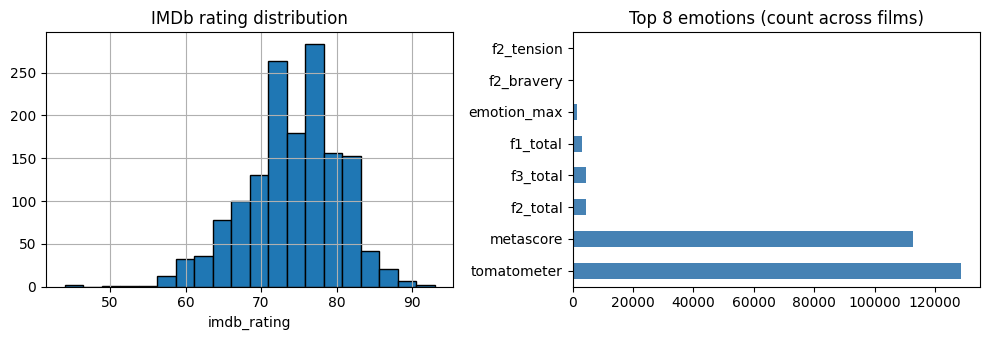


Splits — train 1050, val 225, test 225 | input_dim=156
Naive baseline (always predict majority class): 50.3% accuracy


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Features ---
emotion_cols = [c for c in df.columns if c.startswith(("f1_", "f2_", "f3_"))]
emotions = df[emotion_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)

# Extra signal (not the target): critic scores + compact emotion summaries
extra_cols = ["tomatometer", "metascore"]
extras = df[extra_cols].apply(pd.to_numeric, errors="coerce")
extras = extras.fillna(extras.median())

aggregates = pd.DataFrame({
    "f1_total": emotions[[c for c in emotion_cols if c.startswith("f1_")]].sum(axis=1),
    "f2_total": emotions[[c for c in emotion_cols if c.startswith("f2_")]].sum(axis=1),
    "f3_total": emotions[[c for c in emotion_cols if c.startswith("f3_")]].sum(axis=1),
    "emotion_max": emotions.max(axis=1),
})

X_df = pd.concat([emotions, extras, aggregates], axis=1)
print(f"Features: {len(emotion_cols)} emotions + {len(extra_cols)} critic scores + {len(aggregates.columns)} summaries = {X_df.shape[1]} total")

# Target: high vs low IMDb rating
median_rating = df["imdb_rating"].median()
df["high_rating"] = (df["imdb_rating"] >= median_rating).astype(int)
print(f"\nIMDb rating — min {df['imdb_rating'].min()}, max {df['imdb_rating'].max()}, median {median_rating:.0f}")
print(df["high_rating"].value_counts().rename({0: "low", 1: "high"}))

# Quick plot
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["imdb_rating"].hist(ax=axes[0], bins=20, edgecolor="k")
axes[0].set_title("IMDb rating distribution")
axes[0].set_xlabel("imdb_rating")

top_emotions = X_df.sum().sort_values(ascending=False).head(8)
top_emotions.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Top 8 emotions (count across films)")
plt.tight_layout()
plt.show()

# Train / val / test split (stratified)
X = X_df.values.astype(np.float32)
y = df["high_rating"].values.astype(np.float32)
idx = np.arange(len(df))

X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X, y, idx, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Scale features (fit on train only — emotion scores have very different ranges)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

input_dim = X_train.shape[1]
majority_acc = max(y_train.mean(), 1 - y_train.mean())
print(f"\nSplits — train {len(y_train)}, val {len(y_val)}, test {len(y_test)} | input_dim={input_dim}")
print(f"Naive baseline (always predict majority class): {majority_acc:.1%} accuracy")

## 2. Multi-model search (MLP configs)

Train several **feed-forward MLPs** (2 to 5 hidden layers, up to 512 neurons). Pick the best by **validation accuracy**. Deeper nets use stronger dropout to limit overfitting.

In [28]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


def build_mlp(input_dim, hidden_sizes, dropout=0.0):
    layers = []
    prev = input_dim
    for h in hidden_sizes:
        layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)


def run_config(config, epochs=1000, patience=20):
    """Train one MLP with early stopping; keep weights from best val loss."""
    torch.manual_seed(42)
    model = build_mlp(input_dim, config["hidden"], config.get("dropout", 0)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config.get("weight_decay", 1e-4))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=8)
    loss_fn = nn.BCEWithLogitsLoss()

    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32).unsqueeze(1),
    )
    loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True)

    Xt = torch.tensor(X_train, dtype=torch.float32).to(device)
    yt = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1).to(device)
    Xv = torch.tensor(X_val, dtype=torch.float32).to(device)
    yv = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1).to(device)

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    stale = 0

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            epoch_loss += loss.item() * len(xb)
        history["train_loss"].append(epoch_loss / len(train_ds))

        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(Xt), yt).item()
            val_logits = model(Xv)
            vloss = loss_fn(val_logits, yv).item()
            vacc = ((torch.sigmoid(val_logits) >= 0.5).float() == yv).float().mean().item()
        history["train_loss"][-1] = train_loss  # full-train loss for fair comparison with val
        history["val_loss"].append(vloss)
        history["val_acc"].append(vacc)
        scheduler.step(vloss)

        if vloss < best_val_loss - 1e-4:
            best_val_loss = vloss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


# Several depths — deeper nets need more dropout / weight decay on this small dataset
CONFIGS = [
    {"name": "shallow", "hidden": [128, 64], "lr": 1e-3, "dropout": 0.2, "batch_size": 32},
    {"name": "deep_4L", "hidden": [256, 128, 64, 32], "lr": 1e-3, "dropout": 0.3, "batch_size": 32, "weight_decay": 1e-3},
    {"name": "deep_5L", "hidden": [512, 256, 128, 64, 32], "lr": 5e-4, "dropout": 0.35, "batch_size": 32, "weight_decay": 1e-3},
    {"name": "wide_deep", "hidden": [512, 512, 256, 128], "lr": 5e-4, "dropout": 0.35, "batch_size": 64, "weight_decay": 1e-3},
    {"name": "xlarge", "hidden": [512, 256, 128, 64], "lr": 3e-4, "dropout": 0.3, "batch_size": 32, "weight_decay": 5e-4},
]

results = {}
print("Training configs (early stopping on val loss)...")
for cfg in CONFIGS:
    print(f"  {cfg['name']}: hidden={cfg['hidden']}, lr={cfg['lr']}")
    model, hist = run_config(cfg)
    results[cfg["name"]] = {
        "config": cfg,
        "model": model,
        "history": hist,
        "epochs_run": len(hist["val_loss"]),
        "best_val_loss": min(hist["val_loss"]),
        "best_val_acc": max(hist["val_acc"]),
    }

summary = pd.DataFrame([
    {
        "model": n,
        "epochs": r["epochs_run"],
        "best_val_loss": r["best_val_loss"],
        "best_val_acc": r["best_val_acc"],
        "hidden": str(r["config"]["hidden"]),
        "lr": r["config"]["lr"],
    }
    for n, r in results.items()
]).sort_values("best_val_acc", ascending=False)
display(summary)

best_name = summary.iloc[0]["model"]
best_result = results[best_name]
print(
    f"\nBest model: {best_name} "
    f"(val_acc={best_result['best_val_acc']:.1%}, val_loss={best_result['best_val_loss']:.3f})"
)


Device: cpu
Training configs (early stopping on val loss)...
  shallow: hidden=[128, 64], lr=0.001
  deep_4L: hidden=[256, 128, 64, 32], lr=0.001
  deep_5L: hidden=[512, 256, 128, 64, 32], lr=0.0005
  wide_deep: hidden=[512, 512, 256, 128], lr=0.0005
  xlarge: hidden=[512, 256, 128, 64], lr=0.0003


,model,epochs,best_val_loss,best_val_acc,hidden,lr
4,xlarge,26,0.553078,0.728889,"[512, 256, 128, 64]",0.0003
3,wide_deep,26,0.543096,0.724444,"[512, 512, 256, 128]",0.0005
0,shallow,24,0.541960,0.711111,"[128, 64]",0.0010
1,deep_4L,24,0.550840,0.711111,"[256, 128, 64, 32]",0.0010
2,deep_5L,29,0.548714,0.702222,"[512, 256, 128, 64, 32]",0.0005



Best model: xlarge (val_acc=72.9%, val_loss=0.553)


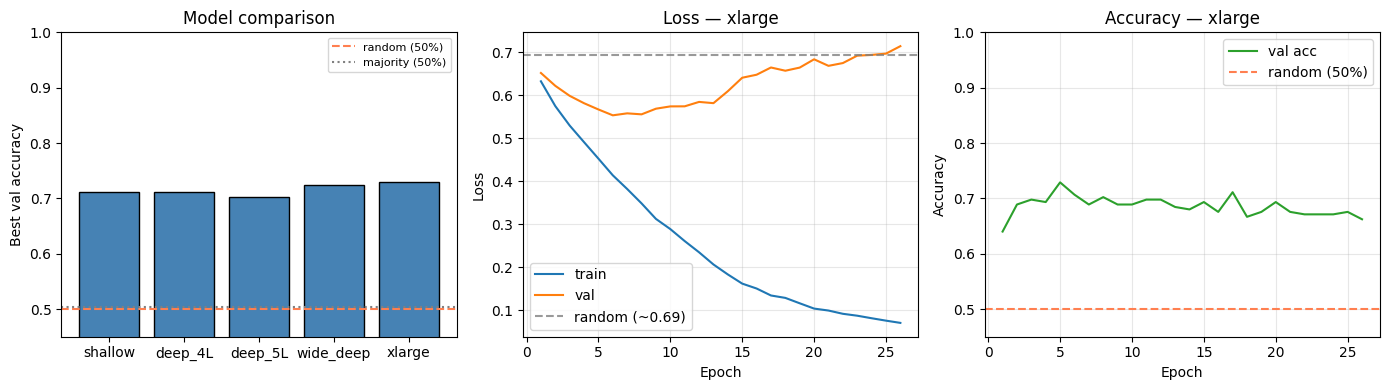

In [29]:
# Clearer visuals: bar chart for model comparison + learning curves for the best model only
random_loss = float(np.log(2))  # ~0.693 for random binary classifier

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1) Best validation accuracy per config (easy to read)
names = list(results.keys())
accs = [results[n]["best_val_acc"] for n in names]
axes[0].bar(names, accs, color="steelblue", edgecolor="k")
axes[0].axhline(0.5, color="coral", ls="--", lw=1.5, label="random (50%)")
axes[0].axhline(majority_acc, color="gray", ls=":", lw=1.5, label=f"majority ({majority_acc:.0%})")
axes[0].set_ylim(0.45, 1.0)
axes[0].set_ylabel("Best val accuracy")
axes[0].set_title("Model comparison")
axes[0].legend(fontsize=8)

# 2–3) Learning curves for the best model only (avoids overlapping lines)
h = best_result["history"]
epochs_r = range(1, len(h["val_loss"]) + 1)
axes[1].plot(epochs_r, h["train_loss"], label="train", color="C0")
axes[1].plot(epochs_r, h["val_loss"], label="val", color="C1")
axes[1].axhline(random_loss, color="gray", ls="--", alpha=0.8, label="random (~0.69)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title(f"Loss — {best_name}")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_r, h["val_acc"], color="C2", label="val acc")
axes[2].axhline(0.5, color="coral", ls="--", label="random (50%)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy")
axes[2].set_ylim(0.45, 1.0)
axes[2].set_title(f"Accuracy — {best_name}")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Best model — test set analysis

**Enhancement:** tune the classification threshold on the validation set (instead of fixed 0.5), then evaluate on the test set.

Best MLP config: xlarge
Val accuracy @ threshold 0.50: 70.7%
Val accuracy @ tuned threshold 0.37: 72.9%
Test accuracy @ 0.50: 75.6%  |  @ tuned: 72.4%

              precision    recall  f1-score   support

         low       0.84      0.55      0.67       112
        high       0.67      0.89      0.77       113

    accuracy                           0.72       225
   macro avg       0.75      0.72      0.72       225
weighted avg       0.75      0.72      0.72       225



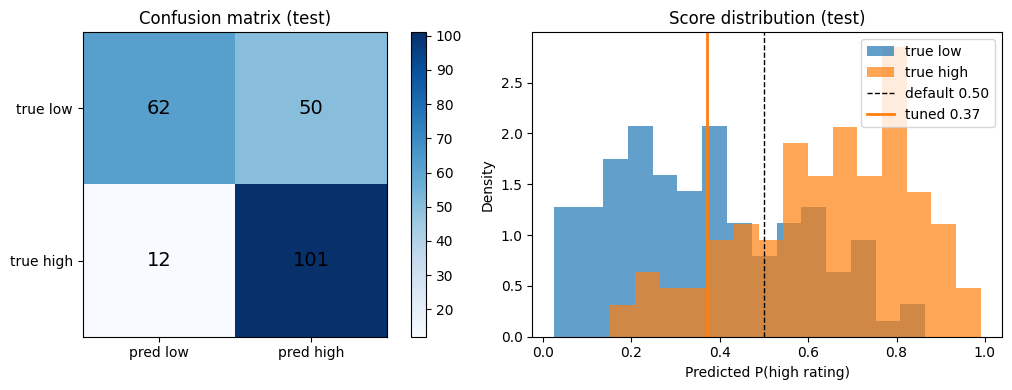


Sample misclassifications (test set):


,title,year,imdb_rating,high_rating,pred,P(high)
400,Far from Heaven,2002,73,0,1,0.679
269,Cocoon,1985,67,0,1,0.404
571,Inland Empire,2006,68,0,1,0.703
931,Seabiscuit,2003,73,0,1,0.738
828,Pirates of the Caribbean: The Curse of the Bla...,2003,81,1,0,0.292


In [30]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

best_model = best_result["model"]
best_model.eval()


def predict_proba(X_np):
    x = torch.tensor(X_np, dtype=torch.float32).to(device)
    with torch.no_grad():
        return torch.sigmoid(best_model(x)).cpu().numpy().ravel()


probs_val = predict_proba(X_val)
probs_test = predict_proba(X_test)
yt = y_test

# Tune threshold on validation only (avoid test leakage)
thresholds = np.linspace(0.05, 0.95, 91)
val_accs = [accuracy_score(y_val, (probs_val >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(val_accs))])

acc_val_05 = accuracy_score(y_val, (probs_val >= 0.5).astype(int))
acc_val_tuned = max(val_accs)
print(f"Best MLP config: {best_name}")
print(f"Val accuracy @ threshold 0.50: {acc_val_05:.1%}")
print(f"Val accuracy @ tuned threshold {best_threshold:.2f}: {acc_val_tuned:.1%}")

probs = probs_test
y_pred = (probs >= best_threshold).astype(int)
acc_test_05 = accuracy_score(yt, (probs >= 0.5).astype(int))
acc_test_tuned = accuracy_score(yt, y_pred)
print(f"Test accuracy @ 0.50: {acc_test_05:.1%}  |  @ tuned: {acc_test_tuned:.1%}\n")
print(classification_report(yt, y_pred, target_names=["low", "high"]))

cm = confusion_matrix(yt, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["pred low", "pred high"])
axes[0].set_yticklabels(["true low", "true high"])
axes[0].set_title("Confusion matrix (test)")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color="k", fontsize=14)
plt.colorbar(im, ax=axes[0], fraction=0.046)

axes[1].hist(probs[yt == 0], bins=15, alpha=0.7, label="true low", density=True)
axes[1].hist(probs[yt == 1], bins=15, alpha=0.7, label="true high", density=True)
axes[1].axvline(0.5, color="k", ls="--", lw=1, label="default 0.50")
axes[1].axvline(best_threshold, color="C1", ls="-", lw=2, label=f"tuned {best_threshold:.2f}")
axes[1].set_xlabel("Predicted P(high rating)")
axes[1].set_ylabel("Density")
axes[1].set_title("Score distribution (test)")
axes[1].legend()

plt.tight_layout()
plt.show()

# Sample misclassified movies
wrong = np.where(y_pred != yt)[0][:5]
if len(wrong):
    print("\nSample misclassifications (test set):")
    sample = df.loc[idx_test[wrong], ["title", "year", "imdb_rating", "high_rating"]].copy()
    sample["pred"] = y_pred[wrong]
    sample["P(high)"] = probs[wrong].round(3)
    display(sample)

## 4. Why this accuracy? & how to improve

### Why we get ~70–85% (not ~99%)

| Factor | Effect |
|--------|--------|
| **Task** | Predicting high vs low IMDb rating from a **median split** — many films sit near the boundary, so errors are expected. |
| **Features** | **Emotions** capture tone but not full audience/critic reception. **Tomatometer / Metascore** add strong signal; without them, accuracy drops toward ~60–65%. |
| **Data size** | ~1,500 films → deep nets help, but there is not enough data to learn very large models without overfitting. |
| **Model** | MLPs model non-linear patterns well on tables, but they are not magic: accuracy reflects how much information is in the inputs. |

**Baseline reminder:** random guess ≈ **50%**; always predicting the majority class ≈ **50%** here (balanced classes). Our model is meaningfully above chance.

### ideas to push accuracy higher

1. **Richer inputs** — plot text (TF‑IDF), year, genre; keep avoiding target leakage (`imdb_rating`, `avg_rating`).
2. **Reframe the target** — 3 rating buckets, or regression on score then threshold.
3. **Stronger tabular models** — Random Forest / XGBoost on the same features (often competitive with MLPs).
4. **Better selection** — k-fold CV, hyperparameter search, ensemble of top MLPs.
5. **More data** — larger catalog would help any model more than adding layers alone.

*For this project, the current pipeline (engineered features + multi-layer MLP + threshold tuning) is a solid balance of performance and simplicity.*